<div align="center">

<h1> <b> UN CALCULADOR EN NUMBA PARA SISTEMAS DEFINIDOS CON UBERMAG </b> </h1>

</div>

<br>

<hr size=10 noshade color="green">
<p>
<p><img alt="UdeA logo" height="180px" src="https://upload.wikimedia.org/wikipedia/commons/archive/f/fb/20161010213812%21Escudo-UdeA.svg" align="left" hspace="100px" vspace="4px"></p>

<div align="right">       

<h3><i> <b>Cristian Camilo Vergara Restrepo</b> <br>
Universidad de Antioquia <br>
Instituto de Física  <br>
</i></h3>
</div>


---

## 1. Objetivo y contexto

Los notebooks `micromagnetic_energy_terms_skyrmion.ipynb` y `torque_magnetometry_uniaxial_box.ipynb` muestran que el tiempo de Ubermag en estos problemas no lo determina el algoritmo de OOMMF, sino el costo fijo de cada llamada: Ubermag escribe los archivos de entrada, lanza OOMMF como proceso externo y lee del disco el resultado, y eso cuesta unos 6 s por llamada en el equipo de las mediciones, casi sin depender del tamaño del problema. El barrido de torque hace 72 llamadas y la verificación de las energías del skyrmion, 13.

La pregunta de este notebook es si Numba puede eliminar ese costo. Numba es un compilador *just-in-time*: traduce a código máquina funciones numéricas de Python, en particular bucles sobre arreglos de `numpy`, la primera vez que se ejecutan (Lam et al., 2015). No puede acelerar el arranque de un programa externo ni la escritura de archivos, de modo que aplicado a las llamadas de `oommfc` no cambiaría nada. Lo que sí permite es hacer el cálculo dentro del propio proceso de Python y no salir de él.

El módulo `scripts/numba_calculator.py` hace eso. Lee el mismo objeto `system` que se le entrega a `oommfc` (malla, términos de energía y magnetización) y resuelve el problema con núcleos compilados por Numba. Su interfaz imita la de `oommfc`:

| Con OOMMF | Con el calculador en Numba |
|---|---|
| `md = oommfc.MinDriver()`; `md.drive(system)` | `md = nc.MinDriver()`; `md.drive(system)` |
| `oommfc.compute(system.energy.zeeman.density, system)` | `nc.compute(system.energy.zeeman.density, system)` |

El notebook repite con ese calculador los dos problemas del proyecto, compara los resultados con los de OOMMF y mide los tiempos de las dos rutas en la misma sesión.

## 2. Método

### 2.1 Términos de energía y discretización

El calculador implementa los cinco términos que usan los dos problemas, sobre la misma malla de celdas y con las mismas reglas de diferencias finitas que OOMMF. El campo efectivo de cada término en la celda $i$, con vecinos $j$ a distancia $\Delta_{ij}$ en la dirección $\hat{\mathbf r}_{ij}$, es

$$
\begin{aligned}
\mathbf H_\mathrm{ex}&=\frac{2A}{\mu_0M_s}\sum_j\frac{\mathbf m_j-\mathbf m_i}{\Delta_{ij}^2}, &
\mathbf H_\mathrm{DMI}&=-\frac{D}{\mu_0M_s}\sum_j\frac{\hat{\mathbf r}_{ij}\times\mathbf m_j}{\Delta_{ij}},\\
\mathbf H_K&=\frac{2K}{\mu_0M_s}(\mathbf m_i\cdot\mathbf u)\,\mathbf u, &
\mathbf H_d(\mathbf r_i)&=-M_s\sum_j\mathsf N(\mathbf r_i-\mathbf r_j)\,\mathbf m_j,
\end{aligned}
$$

más el campo aplicado $\mathbf H$. Las sumas de intercambio y de DMI recorren los seis vecinos; en un borde libre, el vecino que falta no aporta, y con condiciones periódicas se toma la celda del borde opuesto. La suma de la DMI equivale a $-\frac{2D}{\mu_0M_s}\nabla\times\mathbf m$ con diferencias centrales, la forma de la clase cristalina T. Las densidades de energía siguen las convenciones de Ubermag: $w=-\tfrac12\mu_0M_s\,\mathbf m\cdot\mathbf H_t$ para el intercambio, la DMI y el campo desmagnetizante, $w=-\mu_0M_s\,\mathbf m\cdot\mathbf H$ para el término de Zeeman y $w=K\lvert\mathbf m\times\mathbf u\rvert^2$ para la anisotropía.

### 2.2 Campo desmagnetizante

El campo desmagnetizante acopla cada celda con todas las demás. $\mathsf N(\mathbf r)$ es el tensor desmagnetizante entre dos celdas prismáticas uniformemente magnetizadas, con las expresiones analíticas de Newell et al. (1993), que también usa OOMMF. Como la suma es una convolución discreta, se evalúa con la transformada rápida de Fourier sobre una malla del doble de tamaño en cada dirección, rellena con ceros, lo que reduce el costo de $O(N^2)$ a $O(N\log N)$. El tensor y su transformada se calculan una sola vez por malla.

Las expresiones de Newell restan términos grandes y casi iguales, y en doble precisión pierden exactitud al crecer la distancia. Por eso, a partir de 32 celdas de separación se usa la interacción dipolar entre los centros de las celdas, que a esa distancia difiere de la exacta en menos de $10^{-5}$ en términos relativos.

### 2.3 Minimización

`nc.MinDriver` minimiza la energía con un descenso de gradiente sobre la esfera $\lvert\mathbf m\rvert=1$. En cada iteración, con $\mathbf h=\mathbf H_\mathrm{eff}/M_s$ y $\mathbf d=\mathbf m\times(\mathbf m\times\mathbf h)$,

$$\mathbf m'=\frac{\left(1-\tfrac14\tau^2\lvert\mathbf d\rvert^2\right)\mathbf m-\tau\,\mathbf d}{1+\tfrac14\tau^2\lvert\mathbf d\rvert^2},$$

una rotación que conserva la norma de $\mathbf m$ de forma exacta. El paso $\tau$ se elige con las fórmulas de Barzilai y Borwein (1988), alternadas en iteraciones pares e impares, a partir del cambio de $\mathbf m$ y de $\mathbf d$ entre iteraciones consecutivas; es el método de `Minimize()` de MuMax3 (Exl et al., 2014). Se añade un límite: ninguna celda gira más de 0.1 rad por iteración. Lejos del equilibrio el límite manda y el método sigue el camino de la dinámica amortiguada; cerca del equilibrio el par es pequeño, el límite deja de actuar y el paso de Barzilai-Borwein acelera la convergencia. Sin ese límite, los primeros pasos desde el disco inicial del skyrmion son tan largos que la minimización termina en otro equilibrio.

El criterio de parada es el de `MinDriver` de OOMMF en `oommfc` 0.66.0: $\max\lvert\mathbf m\times\mathbf H_\mathrm{eff}\times\mathbf m\rvert<0.1$ A/m.

### 2.4 Qué aporta Numba

Los núcleos (intercambio, DMI, anisotropía, par, actualización de $\mathbf m$ y producto con el tensor en el espacio de Fourier) son bucles explícitos sobre las celdas. En Python puro, cada operación de esos bucles pasa por el intérprete; Numba los compila a código máquina y, en mallas grandes, reparte el bucle externo entre los núcleos del procesador. Las transformadas de Fourier las hace `scipy.fft`, que ya está compilada. La compilación ocurre la primera vez que se usa cada núcleo y se mide aparte en la sección 3.

## 3. Entorno y compilación

La celda importa Ubermag y el calculador, comprueba si OOMMF está disponible y compila los núcleos con un problema mínimo. El notebook debe ejecutarse desde la carpeta del proyecto; `python scripts/run_notebook.py ubermag_numba_calculator.ipynb`, desde una terminal con el entorno de Ubermag activado, lo ejecuta completo y guarda las salidas. Con `RUN_OOMMF = False` se omiten las llamadas a OOMMF, que ocupan casi todo el tiempo del notebook, y la comparación se hace solo con los resultados de Ubermag guardados en `results/`.

In [1]:
import importlib.metadata as imd
import json
import os
import platform
import statistics
import sys
import time
from pathlib import Path

import discretisedfield as df
import matplotlib.pyplot as plt
import micromagneticmodel as mm
import numpy as np

ROOT = Path.cwd()                      # carpeta del proyecto
sys.path.insert(0, str(ROOT / "scripts"))
import numba_calculator as nc


def find_oommf():
    # Devuelve el módulo oommfc si encuentra OOMMF, o None. Un kernel lanzado desde un editor puede
    # arrancar sin activar el entorno de conda; entonces faltan en el PATH las carpetas del entorno
    # donde está el ejecutable oommf, y se añaden como lo haría conda activate.
    import logging
    import shutil
    if shutil.which("oommf") is None:
        prefix = Path(sys.prefix)
        extra = [prefix, prefix / "Library" / "mingw-w64" / "bin", prefix / "Library" / "usr" / "bin",
                 prefix / "Library" / "bin", prefix / "Scripts", prefix / "bin"]
        os.environ["PATH"] = os.pathsep.join([str(d) for d in extra if d.is_dir()] + [os.environ.get("PATH", "")])
    try:
        import oommfc
    except ImportError:
        return None
    logging.getLogger("oommfc").setLevel(logging.ERROR)    # sin avisos de los métodos que no encuentra
    try:
        oommfc.runner.runner
    except Exception:
        return None
    return oommfc


oc = find_oommf()
HAVE_OOMMF = oc is not None

RUN_OOMMF = HAVE_OOMMF                 # False: no se llama a OOMMF (el notebook tarda mucho menos)
N_REP = 3                              # repeticiones de cada medición con el calculador en Numba

t_compile = nc.warm_up()               # compila los núcleos, en serie y en paralelo

versions = {}
for pkg in ("numpy", "scipy", "numba", "discretisedfield", "micromagneticmodel", "oommfc", "mag2exp"):
    try:
        versions[pkg] = imd.version(pkg)
    except imd.PackageNotFoundError:
        versions[pkg] = "no instalado"
environment = {"python": platform.python_version(), "sistema": platform.platform(),
               "procesador": platform.processor(), "nucleos_logicos": os.cpu_count(), **versions,
               "oommf_runner": type(oc.runner.runner).__name__ if HAVE_OOMMF else "no encontrado"}
for key, value in environment.items():
    print(f"{key:20s} {value}")
print(f"\nOOMMF disponible: {HAVE_OOMMF}; se ejecuta: {RUN_OOMMF}")
if not HAVE_OOMMF:
    print("Este kernel no encuentra OOMMF. Para comparar con OOMMF en la misma sesión, ejecuta el notebook\n"
          "desde una terminal con el entorno de Ubermag activado:\n"
          "    python scripts/run_notebook.py ubermag_numba_calculator.ipynb")
print(f"Compilación de los núcleos de Numba: {t_compile:.1f} s")


def timed(func, *args, **kwargs):
    # Ejecuta func y devuelve (resultado, tiempo de pared en s)
    start = time.perf_counter()
    out = func(*args, **kwargs)
    return out, time.perf_counter() - start


def unit(field):
    # Dirección de la magnetización como arreglo (nx, ny, nz, 3)
    a = np.asarray(field.array if hasattr(field, "array") else field, dtype=float)
    return a / np.linalg.norm(a, axis=-1, keepdims=True)


def max_dm(a, b):
    # Diferencia máxima |m_a - m_b| celda a celda
    return float(np.linalg.norm(unit(a) - unit(b), axis=-1).max())

python               3.12.14
sistema              Windows-11-10.0.26300-SP0
procesador           Intel64 Family 6 Model 183 Stepping 1, GenuineIntel
nucleos_logicos      24
numpy                2.5.4
scipy                1.18.1
numba                0.68.0
discretisedfield     0.92.0
micromagneticmodel   0.65.0
oommfc               0.66.0
mag2exp              0.64.0
oommf_runner         ExeOOMMFRunner

OOMMF disponible: True; se ejecuta: True
Compilación de los núcleos de Numba: 6.7 s


## 4. Energías de un skyrmion

El sistema es el de `micromagnetic_energy_terms_skyrmion.ipynb`: una película de FeGe de $100\times100\times5$ nm$^3$, periódica en $x$ e $y$, con intercambio, DMI de clase T, anisotropía uniaxial y campo de Zeeman, que parte de un disco central con la magnetización invertida. La función `skyrmion_system` lo define con las mismas instrucciones de Ubermag, y `skyrmion_workflow` repite el flujo de ese notebook con el calculador que reciba: una minimización y, para cada uno de los cuatro términos, la densidad de energía, la energía total y el campo efectivo, 13 cálculos en total. Cada resultado se compara además con la expresión escrita con operaciones de `discretisedfield`, como en el notebook original.

In [2]:
L, thickness = 100e-9, 5e-9
Ms_sk, A_sk, D_sk, K_sk = 3.84e5, 8.78e-12, 1.58e-3, 1e4
u_sk, H_sk = (0, 0, 1), (0, 0, 1e5)


def m_initial(point):
    x, y, z = point
    return (0, 0, -1) if x**2 + y**2 < (L / 4) ** 2 else (0, 0, 1)


def skyrmion_system(name):
    region = df.Region(p1=(-L / 2, -L / 2, 0), p2=(L / 2, L / 2, thickness))
    mesh = df.Mesh(region=region, cell=(5e-9, 5e-9, 5e-9), bc="xy")
    system = mm.System(name=name)
    system.energy = (mm.Exchange(A=A_sk) + mm.DMI(D=D_sk, crystalclass="T")
                     + mm.Zeeman(H=H_sk) + mm.UniaxialAnisotropy(K=K_sk, u=u_sk))
    system.m = df.Field(mesh, nvdim=3, value=m_initial, norm=Ms_sk)
    return system


def skyrmion_workflow(driver, compute, system):
    # Una minimización y 12 consultas (densidad, energía y campo efectivo de 4 términos)
    _, t_relax = timed(driver.drive, system)
    energy = system.energy
    terms = {"Zeeman": energy.zeeman, "Anisotropía": energy.uniaxialanisotropy,
             "Intercambio": energy.exchange, "DMI": energy.dmi}
    out = {"t_relax": t_relax, "energies": {}, "density": {}, "field": {}}
    start = time.perf_counter()
    for label, term in terms.items():
        out["density"][label] = compute(term.density, system)
        out["energies"][label] = compute(term.energy, system)
        out["field"][label] = compute(term.effective_field, system)
    out["t_terms"] = time.perf_counter() - start
    return out


def formulas(system):
    # Las expresiones del notebook original, con operaciones de discretisedfield
    m, mu0 = system.m.orientation, mm.consts.mu0
    mxu = abs(m.cross(u_sk))
    density = {"Zeeman": -mu0 * Ms_sk * m.dot(H_sk), "Anisotropía": K_sk * mxu.dot(mxu),
               "Intercambio": -A_sk * m.dot(m.laplace), "DMI": D_sk * m.dot(m.curl)}
    field = {"Zeeman": df.Field(m.mesh, nvdim=3, value=H_sk),
             "Anisotropía": 2 * K_sk / (mu0 * Ms_sk) * (m.dot(u_sk)) * u_sk,
             "Intercambio": 2 * A_sk / (mu0 * Ms_sk) * m.laplace,
             "DMI": -2 * D_sk / (mu0 * Ms_sk) * m.curl}
    return density, field


# --- Calculador en Numba: N_REP repeticiones desde el estado inicial -------------------------
runs_nb = []
for _ in range(N_REP):
    sk_nb = skyrmion_system("skyrmion_numba")
    md_nb = nc.MinDriver()
    runs_nb.append(skyrmion_workflow(md_nb, nc.compute, sk_nb))
sk_res_nb = runs_nb[-1]
t_sk_nb = {"relax": statistics.median(r["t_relax"] for r in runs_nb),
           "terms": statistics.median(r["t_terms"] for r in runs_nb)}
print(f"Numba: minimización en {md_nb.info['iterations']} iteraciones, "
      f"máx |m x H x m| = {md_nb.info['max_mxHxm']:.3f} A/m, <m_z> = {unit(sk_nb.m)[..., 2].mean():.5f}")
print(f"       tiempos (mediana de {N_REP}): minimización {t_sk_nb['relax'] * 1e3:.1f} ms, "
      f"12 consultas {t_sk_nb['terms'] * 1e3:.1f} ms")

density_df, field_df = formulas(sk_nb)
print("\nComprobación con las expresiones de discretisedfield (calculador en Numba):")
for label in density_df:
    e_df = float(np.ravel(density_df[label].integrate())[0])
    print(f"  {label:12s} densidad: {density_df[label].allclose(sk_res_nb['density'][label])}  "
          f"campo: {field_df[label].allclose(sk_res_nb['field'][label])}  "
          f"energía df {e_df: .8e} | Numba {sk_res_nb['energies'][label]: .8e}")

# --- OOMMF ----------------------------------------------------------------------------------
sk_res_oo, t_sk_oo = None, None
if RUN_OOMMF:
    sk_oo = skyrmion_system("skyrmion_oommf")
    sk_res_oo = skyrmion_workflow(oc.MinDriver(), oc.compute, sk_oo)
    t_sk_oo = {"relax": sk_res_oo["t_relax"], "terms": sk_res_oo["t_terms"]}
    print(f"\nOOMMF: minimización {t_sk_oo['relax']:.2f} s, 12 consultas {t_sk_oo['terms']:.2f} s")

Numba: minimización en 131 iteraciones, máx |m x H x m| = 0.081 A/m, <m_z> = 0.42886
       tiempos (mediana de 3): minimización 2.6 ms, 12 consultas 1.0 ms

Comprobación con las expresiones de discretisedfield (calculador en Numba):
  Zeeman       densidad: True  campo: True  energía df -1.03472232e-18 | Numba -1.03472232e-18
  Anisotropía  densidad: True  campo: True  energía df  2.04335553e-19 | Numba  2.04335553e-19
  Intercambio  densidad: True  campo: True  energía df  1.74383708e-18 | Numba  1.74383708e-18
  DMI          densidad: True  campo: True  energía df -4.35058749e-18 | Numba -4.35058749e-18
Running OOMMF (ExeOOMMFRunner)[2026-11-18T18:24:59]... 

(7.7 s)
Running OOMMF (ExeOOMMFRunner)[2026-11-18T18:25:07]... 

(6.2 s)
Running OOMMF (ExeOOMMFRunner)[2026-11-18T18:25:13]... 

(6.1 s)
Running OOMMF (ExeOOMMFRunner)[2026-11-18T18:25:20]... 

(6.3 s)
Running OOMMF (ExeOOMMFRunner)[2026-11-18T18:25:26]... 

(6.1 s)
Running OOMMF (ExeOOMMFRunner)[2026-11-18T18:25:32]... 

... (4 outputs left out)

(6.3 s)
Running OOMMF (ExeOOMMFRunner)[2026-11-18T18:26:03]... 

(6.3 s)
Running OOMMF (ExeOOMMFRunner)[2026-11-18T18:26:09]... 

(6.2 s)
Running OOMMF (ExeOOMMFRunner)[2026-11-18T18:26:16]... 

(6.3 s)

OOMMF: minimización 7.79 s, 12 consultas 74.57 s


La celda siguiente compara el estado relajado y las energías del calculador en Numba con los de OOMMF de esta sesión, si se ejecutó, y con el estado de Ubermag guardado en `results/`.

In [3]:
REF_ENERGIES = {"Zeeman": -1.03472186e-18, "Anisotropía": 2.0433559e-19,
                "Intercambio": 1.74383742e-18, "DMI": -4.35058832e-18}   # documentación de Ubermag

sk_compare = {"energias_rel_documentacion": {}, "energias_rel_oommf": {}}
print("Energías (J): Numba | referencia de la documentación | dif. rel." + (" | OOMMF | dif. rel." if sk_res_oo else ""))
for label, ref in REF_ENERGIES.items():
    e_nb = sk_res_nb["energies"][label]
    sk_compare["energias_rel_documentacion"][label] = abs(e_nb - ref) / abs(ref)
    line = f"  {label:12s} {e_nb: .8e} | {ref: .8e} | {abs(e_nb - ref) / abs(ref):.1e}"
    if sk_res_oo:
        e_oo = sk_res_oo["energies"][label]
        sk_compare["energias_rel_oommf"][label] = abs(e_nb - e_oo) / abs(e_oo)
        line += f" | {e_oo: .8e} | {abs(e_nb - e_oo) / abs(e_oo):.1e}"
    print(line)

if sk_res_oo:
    sk_compare["max_dm_oommf"] = max_dm(sk_nb.m, sk_oo.m)
    print(f"\nEstado relajado: máx |dm| Numba - OOMMF (esta sesión) = {sk_compare['max_dm_oommf']:.1e}")
ref_file = ROOT / "results" / "ubermag_arrays_micromagnetic_energy_terms_skyrmion.npz"
if ref_file.exists():
    sk_compare["max_dm_ubermag_guardado"] = max_dm(sk_nb.m, np.load(ref_file)["m_relaxed"])
    print(f"Estado relajado: máx |dm| Numba - Ubermag guardado = {sk_compare['max_dm_ubermag_guardado']:.1e}")

Energías (J): Numba | referencia de la documentación | dif. rel. | OOMMF | dif. rel.
  Zeeman       -1.03472232e-18 | -1.03472186e-18 | 4.4e-07 | -1.03472186e-18 | 4.4e-07
  Anisotropía   2.04335553e-19 |  2.04335590e-19 | 1.8e-07 |  2.04335590e-19 | 1.8e-07
  Intercambio   1.74383708e-18 |  1.74383742e-18 | 2.0e-07 |  1.74383742e-18 | 2.0e-07
  DMI          -4.35058749e-18 | -4.35058832e-18 | 1.9e-07 | -4.35058832e-18 | 1.9e-07

Estado relajado: máx |dm| Numba - OOMMF (esta sesión) = 5.6e-07
Estado relajado: máx |dm| Numba - Ubermag guardado = 5.6e-07


## 5. Magnetometría de torque

El sistema es el de `torque_magnetometry_uniaxial_box.ipynb`: una caja de $300\times300\times100$ nm$^3$ ($60\times60\times20$ celdas) con intercambio, anisotropía uniaxial en $z$, campo desmagnetizante y un campo de $2.38\times10^{6}$ A/m que rota en el plano $yz$. `torque_workflow` repite el flujo de ese notebook: una minimización a campo cero y otra en cada uno de los 71 ángulos, partiendo del estado del ángulo anterior, con el torque $\boldsymbol\tau=\mu_0\langle\mathbf M\rangle\times\mathbf H$ calculado con `mag2exp` en las dos rutas. Se registra el tiempo de cada llamada a `drive`.

In [4]:
import mag2exp

Ms_box, H_mag = 9.65e5, 2.38e6
angles = np.linspace(0, 2 * np.pi, 71)


def box_system(name):
    region = df.Region(p1=(-150e-9, -150e-9, 0), p2=(150e-9, 150e-9, 100e-9))
    mesh = df.Mesh(region=region, cell=(5e-9, 5e-9, 5e-9))
    system = mm.System(name=name)
    system.energy = (mm.Exchange(A=8.78e-13) + mm.UniaxialAnisotropy(K=1.18e6, u=(0, 0, 1))
                     + mm.Demag() + mm.Zeeman(H=(0, 0, 0)))
    system.m = df.Field(mesh, nvdim=3, value=(0, 0, 1), norm=Ms_box)
    return system


def torque_workflow(driver, system):
    # Relajación a campo cero y barrido de 71 ángulos; devuelve el torque y el tiempo de cada drive
    _, t_zero = timed(driver.drive, system)
    mz_zero = float(unit(system.m)[..., 2].mean())
    torque = np.full((len(angles), 3), np.nan)
    t_calls = np.full(len(angles), np.nan)
    for i, angle in enumerate(angles):
        system.energy.zeeman.H = (0, H_mag * np.sin(angle), H_mag * np.cos(angle))
        _, t_calls[i] = timed(driver.drive, system, verbose=0)
        torque[i] = mag2exp.magnetometry.torque(system.m, system.energy.zeeman.H)
    return {"t_zero": t_zero, "mz_zero": mz_zero, "torque": torque, "t_calls": t_calls,
            "t_total": t_zero + float(t_calls.sum())}


# --- Calculador en Numba ----------------------------------------------------------------------
box_nb = box_system("Box2_numba")
_, t_kernel = timed(nc.demag_kernel, box_nb.m.mesh.n, box_nb.m.mesh.cell)   # tensor de Newell y su FFT
runs_nb = [torque_workflow(nc.MinDriver(), box_system("Box2_numba")) for _ in range(N_REP)]
tq_nb = runs_nb[-1]
t_tq_nb = statistics.median(r["t_total"] for r in runs_nb)
print(f"Numba: tensor desmagnetizante en {t_kernel:.2f} s (una vez por malla)")
print(f"       72 minimizaciones en {t_tq_nb:.2f} s (mediana de {N_REP}; "
      f"mín. {min(r['t_total'] for r in runs_nb):.2f}, máx. {max(r['t_total'] for r in runs_nb):.2f}); "
      f"mediana por llamada {np.median(tq_nb['t_calls']) * 1e3:.0f} ms")
print(f"       <m_z> a campo cero = {tq_nb['mz_zero']:.5f}; tau_x máx. = {tq_nb['torque'][:, 0].max():.6e} N/m2")

# --- OOMMF (71 + 1 llamadas) --------------------------------------------------------------------
tq_oo = None
if RUN_OOMMF:
    tq_oo = torque_workflow(oc.MinDriver(), box_system("Box2_oommf"))
    print(f"\nOOMMF: 72 llamadas en {tq_oo['t_total']:.1f} s; mediana por llamada {np.median(tq_oo['t_calls']):.2f} s")
    print(f"       <m_z> a campo cero = {tq_oo['mz_zero']:.5f}; tau_x máx. = {tq_oo['torque'][:, 0].max():.6e} N/m2")

Numba: tensor desmagnetizante en 0.10 s (una vez por malla)
       72 minimizaciones en 21.60 s (mediana de 3; mín. 21.07, máx. 21.76); mediana por llamada 220 ms
       <m_z> a campo cero = 0.99782; tau_x máx. = 9.487023e+05 N/m2
Running OOMMF (ExeOOMMFRunner)[2026-11-18T18:27:28]... 

(6.2 s)



OOMMF: 72 llamadas en 462.2 s; mediana por llamada 6.42 s
       <m_z> a campo cero = 0.99782; tau_x máx. = 9.487023e+05 N/m2


In [5]:
tq_compare = {}
amp = 0.5 * (tq_nb["torque"][:, 0].max() - tq_nb["torque"][:, 0].min())
references = {}
if tq_oo is not None:
    references["OOMMF (esta sesión)"] = tq_oo["torque"][:, 0]
ref_file = ROOT / "results" / "ubermag_arrays_torque_magnetometry_uniaxial_box.npz"
if ref_file.exists():
    references["Ubermag guardado"] = np.load(ref_file)["tx"]
mumax_file = ROOT / "mumax3" / "torque_magnetometry_mumax3.out" / "torque_vs_angle.txt"
if mumax_file.exists():
    references["MuMax3"] = np.loadtxt(mumax_file)[:, 1]
print(f"Amplitud de tau_x (Numba): {amp:.6e} N/m2")
for label, tx in references.items():
    diff = np.abs(tq_nb["torque"][:, 0] - tx).max()
    tq_compare[label] = diff / amp
    print(f"  Numba - {label:20s}: diferencia máxima {diff:.3e} N/m2 = {diff / amp:.1e} de la amplitud")

Amplitud de tau_x (Numba): 9.487023e+05 N/m2
  Numba - OOMMF (esta sesión) : diferencia máxima 6.584e-03 N/m2 = 6.9e-09 de la amplitud
  Numba - Ubermag guardado    : diferencia máxima 6.584e-03 N/m2 = 6.9e-09 de la amplitud
  Numba - MuMax3              : diferencia máxima 3.736e+01 N/m2 = 3.9e-05 de la amplitud


## 6. Resumen, figura y archivos de resultados

La celda reúne los tiempos de las dos rutas, dibuja la curva de torque de cada una, su diferencia y los tiempos, y guarda los resultados en `results/numba_calculator_results.json` y `results/numba_calculator_arrays.npz` y la figura en `figures/fig_numba_calculator.png`.

Tarea                                        Numba (s)   OOMMF (s)  Cociente
Skyrmion: 1 minimización + 12 consultas         0.0036       82.36     22893
Torque: 72 minimizaciones                      21.6000      462.18        21

Costos que se pagan una vez: compilación de Numba 6.7 s; tensor desmagnetizante 0.10 s


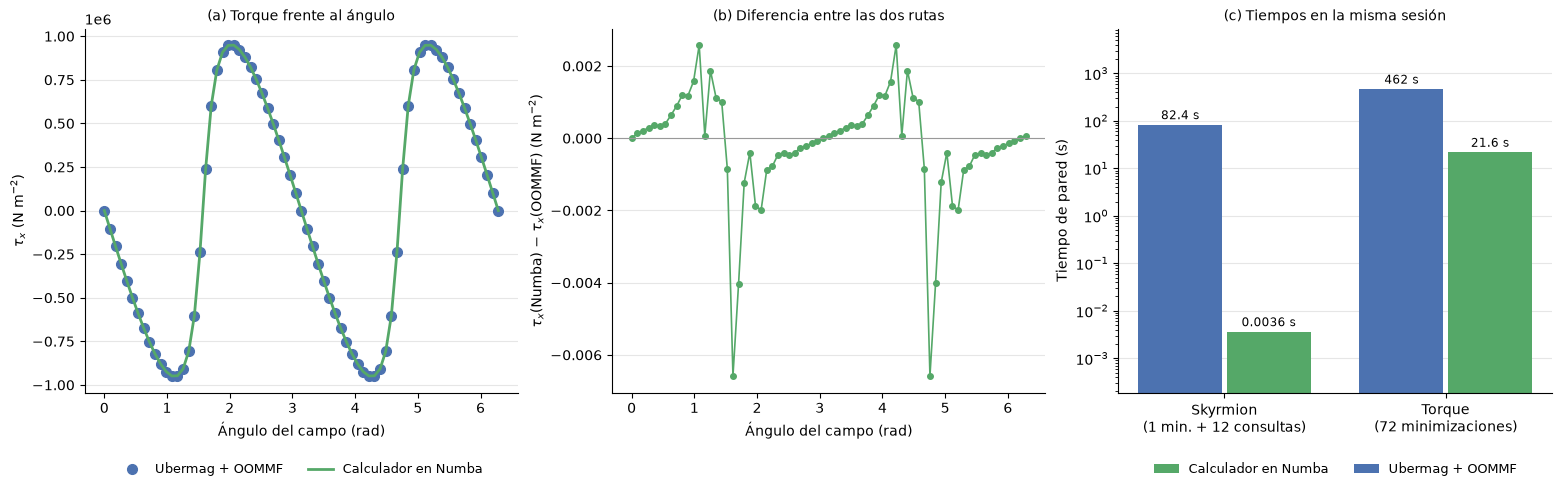

Guardado: results/numba_calculator_results.json, results/numba_calculator_arrays.npz, figures/fig_numba_calculator.png


In [6]:
C_OOMMF, C_NUMBA = "#4C72B0", "#55A868"

times = {
    "compilacion_numba_s": t_compile,
    "tensor_desmagnetizante_s": t_kernel,
    "skyrmion": {"numba_minimizacion_s": t_sk_nb["relax"], "numba_12_consultas_s": t_sk_nb["terms"],
                 "oommf_minimizacion_s": t_sk_oo["relax"] if t_sk_oo else None,
                 "oommf_12_consultas_s": t_sk_oo["terms"] if t_sk_oo else None},
    "torque": {"numba_72_minimizaciones_s": t_tq_nb,
               "numba_repeticiones_s": [r["t_total"] for r in runs_nb],
               "numba_mediana_por_llamada_s": float(np.median(tq_nb["t_calls"])),
               "oommf_72_llamadas_s": tq_oo["t_total"] if tq_oo else None,
               "oommf_mediana_por_llamada_s": float(np.median(tq_oo["t_calls"])) if tq_oo else None},
}

rows = [("Skyrmion: 1 minimización + 12 consultas", t_sk_nb["relax"] + t_sk_nb["terms"],
         t_sk_oo["relax"] + t_sk_oo["terms"] if t_sk_oo else None),
        ("Torque: 72 minimizaciones", t_tq_nb, tq_oo["t_total"] if tq_oo else None)]
print(f"{'Tarea':42s} {'Numba (s)':>11s} {'OOMMF (s)':>11s} {'Cociente':>9s}")
for label, t_nb, t_oo in rows:
    extra = f"{t_oo:11.2f} {t_oo / t_nb:9.0f}" if t_oo else f"{'no medido':>11s} {'':>9s}"
    print(f"{label:42s} {t_nb:11.4f} {extra}")
print(f"\nCostos que se pagan una vez: compilación de Numba {t_compile:.1f} s; tensor desmagnetizante {t_kernel:.2f} s")

plt.style.use("default")              # Ubermag cambia el estilo de matplotlib al importarse
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.8), layout="constrained")
ax = axes[0]
if tq_oo is not None:
    ax.plot(angles, tq_oo["torque"][:, 0], "o", ms=7, color=C_OOMMF, label="Ubermag + OOMMF")
elif "Ubermag guardado" in references:
    ax.plot(angles, references["Ubermag guardado"], "o", ms=7, color=C_OOMMF, label="Ubermag + OOMMF (guardado)")
ax.plot(angles, tq_nb["torque"][:, 0], "-", lw=2, color=C_NUMBA, label="Calculador en Numba")
ax.set_xlabel("Ángulo del campo (rad)")
ax.set_ylabel(r"$\tau_x$ (N m$^{-2}$)")
ax.set_title("(a) Torque frente al ángulo", fontsize=10)
ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)

ax = axes[1]
ref_label = "OOMMF (esta sesión)" if tq_oo is not None else ("Ubermag guardado" if "Ubermag guardado" in references else None)
if ref_label:
    ax.plot(angles, tq_nb["torque"][:, 0] - references[ref_label], "-o", ms=4, lw=1.2, color=C_NUMBA)
    ax.axhline(0, color="0.6", lw=0.8)
ax.set_xlabel("Ángulo del campo (rad)")
ax.set_ylabel(r"$\tau_x$(Numba) $-$ $\tau_x$(OOMMF) (N m$^{-2}$)")
ax.set_title("(b) Diferencia entre las dos rutas", fontsize=10)

ax = axes[2]
labels = ["Skyrmion\n(1 min. + 12 consultas)", "Torque\n(72 minimizaciones)"]
x = np.arange(len(labels))
t_nb_vals = [rows[0][1], rows[1][1]]
bars = ax.bar(x + 0.2, t_nb_vals, 0.38, color=C_NUMBA, label="Calculador en Numba")
ax.bar_label(bars, labels=[f"{t:.3g} s" for t in t_nb_vals], fontsize=8.5, padding=2)
if t_sk_oo and tq_oo:
    t_oo_vals = [rows[0][2], rows[1][2]]
    bars = ax.bar(x - 0.2, t_oo_vals, 0.38, color=C_OOMMF, label="Ubermag + OOMMF")
    ax.bar_label(bars, labels=[f"{t:.3g} s" for t in t_oo_vals], fontsize=8.5, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, labels)
ax.set_ylabel("Tiempo de pared (s)")
ax.set_title("(c) Tiempos en la misma sesión", fontsize=10)
ax.margins(y=0.25)
ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
for a in axes:
    a.grid(True, axis="y", color="0.9", lw=0.8)
    a.set_axisbelow(True)
    a.spines[["top", "right"]].set_visible(False)

(ROOT / "figures").mkdir(exist_ok=True)
(ROOT / "results").mkdir(exist_ok=True)
fig.savefig(ROOT / "figures" / "fig_numba_calculator.png", dpi=150, bbox_inches="tight")
plt.show()

results = {"fecha": time.strftime("%Y-%m-%d %H:%M"), "entorno": environment, "oommf_ejecutado": bool(RUN_OOMMF),
           "repeticiones_numba": N_REP, "tiempos": times,
           "skyrmion": {"iteraciones": md_nb.info["iterations"], "max_mxHxm_A_m": md_nb.info["max_mxHxm"],
                        "mz_medio": float(unit(sk_nb.m)[..., 2].mean()),
                        "energias_J": sk_res_nb["energies"], **sk_compare},
           "torque": {"amplitud_N_m2": float(amp), "mz_campo_cero": tq_nb["mz_zero"],
                      "diferencia_maxima_sobre_amplitud": tq_compare}}
(ROOT / "results" / "numba_calculator_results.json").write_text(json.dumps(results, indent=2, ensure_ascii=False), encoding="utf-8")
arrays = {"angles": angles, "torque_numba": tq_nb["torque"], "t_calls_numba": tq_nb["t_calls"],
          "m_skyrmion_numba": unit(sk_nb.m)}
if tq_oo is not None:
    arrays.update(torque_oommf=tq_oo["torque"], t_calls_oommf=tq_oo["t_calls"])
if sk_res_oo is not None:
    arrays["m_skyrmion_oommf"] = unit(sk_oo.m)
np.savez_compressed(ROOT / "results" / "numba_calculator_arrays.npz", **arrays)
print("Guardado: results/numba_calculator_results.json, results/numba_calculator_arrays.npz, figures/fig_numba_calculator.png")

## 7. Discusión

**Concordancia.** El calculador en Numba y OOMMF resuelven el mismo modelo con las mismas diferencias finitas y se detienen con el mismo criterio, aunque llegan al equilibrio por caminos distintos: gradiente conjugado en OOMMF y pasos de Barzilai-Borwein aquí.

| Comparación con OOMMF (misma sesión) | Diferencia máxima |
|---|---:|
| Energías del skyrmion (cuatro términos), relativa | $4.4\times10^{-7}$ |
| Estado relajado del skyrmion, por celda | $5.6\times10^{-7}$ |
| Curva de torque, relativa a la amplitud | $6.9\times10^{-9}$ |

Las diferencias son compatibles con el umbral de parada, 0.1 A/m, comparado con los campos efectivos de cada problema, del orden de $10^{5}$ A/m en el skyrmion y de $10^{6}$ A/m en la caja. Como el calculador trabaja en doble precisión y parte del disco simétrico, se detiene, igual que OOMMF, en el equilibrio simétrico del skyrmion, que la sección 8.2 de `micromagnetic_energy_terms_skyrmion.ipynb` identifica como un punto de silla. La curva de torque de MuMax3 difiere de la del calculador en $3.9\times10^{-5}$ de la amplitud, lo mismo que la separa de la de OOMMF.

**Tiempos.** Las dos rutas se midieron en la misma sesión:

| Tarea | Ubermag + OOMMF | Calculador en Numba | Cociente |
|---|---:|---:|---:|
| Skyrmion: 1 minimización y 12 consultas | 82.4 s (13 llamadas) | 3.6 ms | $2.3\times10^{4}$ |
| Torque: 72 minimizaciones con 72 000 celdas | 462.2 s | 21.6 s | 21 |

La compilación de los núcleos (6.7 s) se paga una vez por sesión de Python y el tensor desmagnetizante (0.10 s), una vez por malla. Aun sumándolos, el barrido de torque tarda 28.4 s, 16 veces menos que con OOMMF.

Los dos cocientes son tan distintos porque miden cosas distintas.

- En el skyrmion, con 400 celdas, el cálculo es despreciable. Las 13 llamadas a OOMMF tardan unos 6.3 s cada una, casi todo en lanzar el proceso y escribir y leer archivos, y el calculador hace el mismo trabajo en milisegundos.
- En el barrido de torque, cada llamada a OOMMF tarda 6.42 s (mediana) y cada minimización del calculador, 0.22 s. Con `scripts/benchmark_scaling.py`, en este equipo, una llamada a OOMMF con esta malla se separó en 6.15 s de costo fijo y unos 0.33 s de cálculo. El calculador tarda por minimización lo mismo, en orden de magnitud, que la parte de cálculo de OOMMF: el factor 21 viene de quitar el costo fijo, no de un algoritmo más rápido.
- MuMax3 hace el mismo barrido en 1.5 s en la GPU, unas 0.02 s de cálculo por ángulo: unas diez veces menos que el calculador, que calcula en CPU.

**Respuesta a la pregunta del notebook.** Numba no acelera las llamadas de Ubermag a OOMMF, porque su costo no es código de Python. Permite, en cambio, evitarlas: con un calculador que lee el mismo `system` y resuelve el problema dentro del proceso de Python, desaparece el costo fijo de cada llamada. Un flujo de trabajo de muchas consultas pequeñas, como la verificación de las energías del skyrmion, pasa de minutos a milisegundos; un barrido grande, como el de torque, queda limitado por el propio cálculo, donde la GPU de MuMax3 sigue siendo más rápida.

## 8. Alcance y limitaciones

- El calculador cubre los términos y las mallas de los dos problemas del proyecto: intercambio, anisotropía uniaxial, Zeeman, DMI de clase T y campo desmagnetizante en mallas sin periodicidad, con $M_s$ uniforme. OOMMF es un programa general, con muchos más términos, geometrías arbitrarias, regiones con materiales distintos y evolución temporal; el calculador no lo sustituye.
- Solo minimiza la energía. No integra la ecuación de Landau-Lifshitz-Gilbert en el tiempo.
- La compilación de Numba se paga en cada sesión nueva de Python, y el tensor desmagnetizante, una vez por malla. En un cálculo aislado y pequeño, esos costos pueden superar al del propio cálculo.
- Los tiempos corresponden a un equipo y a una instalación. El costo de cada llamada a OOMMF, que es lo que el calculador evita, depende del sistema operativo y del equipo.
- El tiempo de MuMax3 y la separación entre el costo fijo y el de cálculo de OOMMF proceden de mediciones en otra sesión, en el mismo equipo (`torque_magnetometry_uniaxial_box.ipynb`, sección 8.4).
- Las transformadas de Fourier no las acelera Numba: las hace `scipy.fft`. En el problema de torque, donde domina el campo desmagnetizante, el tiempo depende sobre todo de esa biblioteca.

## Referencias

**Fuentes académicas**

Barzilai, J., & Borwein, J. M. (1988). Two-point step size gradient methods. *IMA Journal of Numerical Analysis, 8*(1), 141-148. https://doi.org/10.1093/imanum/8.1.141

Beg, M., Lang, M., & Fangohr, H. (2022). Ubermag: Toward more effective micromagnetic workflows. *IEEE Transactions on Magnetics, 58*(2), 1-5. https://doi.org/10.1109/TMAG.2021.3078896

Exl, L., Bance, S., Reichel, F., Schrefl, T., Peter Stimming, H., & Mauser, N. J. (2014). LaBonte's method revisited: An effective steepest descent method for micromagnetic energy minimization. *Journal of Applied Physics, 115*(17), 17D118. https://doi.org/10.1063/1.4862839

Lam, S. K., Pitrou, A., & Seibert, S. (2015). Numba: A LLVM-based Python JIT compiler. En *Proceedings of the Second Workshop on the LLVM Compiler Infrastructure in HPC* (artículo 7). Association for Computing Machinery. https://doi.org/10.1145/2833157.2833162

Newell, A. J., Williams, W., & Dunlop, D. J. (1993). A generalization of the demagnetizing tensor for nonuniform magnetization. *Journal of Geophysical Research: Solid Earth, 98*(B6), 9551-9555. https://doi.org/10.1029/93JB00694

**Documentación de software**

Donahue, M. J., & Porter, D. G. (1999). *OOMMF user's guide, version 1.0* (NISTIR 6376). National Institute of Standards and Technology. https://doi.org/10.6028/NIST.IR.6376

Ubermag developers. (s. f.). *oommfc* (versión 0.66.0) [Código fuente]. GitHub. https://github.com/ubermag/oommfc